In [1]:
import numpy as np
import matplotlib.pyplot as plt

In this notebook we will consider different numerical methods for solving a simple ODE $$\dot{x}=x(1-x),$$ on the interval $0 \le t \le 10$ with $\Delta t = 0.1$ with $x(0)=0.5$.


First, let's define our function

In [2]:
def dxdt(x):
    return x*(1-x)

Next we should specify the parameters of our numerical method

In [36]:
dt = 0.1
t_start = 0
t_final = 10
x0 = 0.5
t = np.arange(t_start, t_final+dt, dt)

# Define x array to fill with solutions
x = np.zeros(t.shape)
x[0] = x0

## Euler's method 
$$x_{n+1}=x_n+\Delta t f(x_n).$$


In [37]:
x1 = x0 + dt*dxdt(x0)
print(x1)

0.525


In [38]:
for j in range(t.shape[0]-1):
    x[j+1] = x[j] + dt * dxdt(x[j])

Plotting our solution

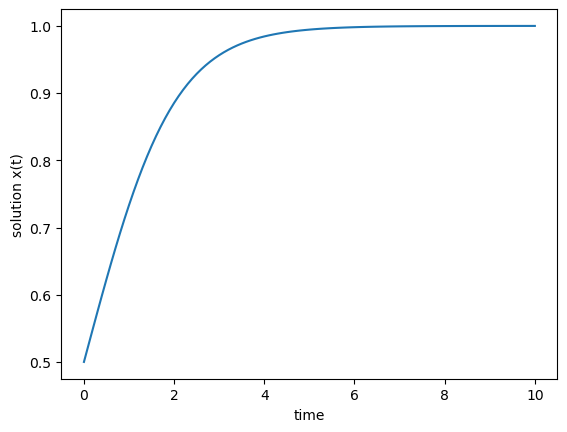

In [39]:
plt.plot(t, x)
plt.xlabel("time")
plt.ylabel("solution x(t)");
# x(t) tends to 1 which makes sense as we found that it has a stable fixed point at 1

Now suppose we were asked to solve the equation for a range of initial conditions between $0 \le x_0 \le 2$ in steps of 0.1. Extend the code above to compute the solution for multiple initial conditions.

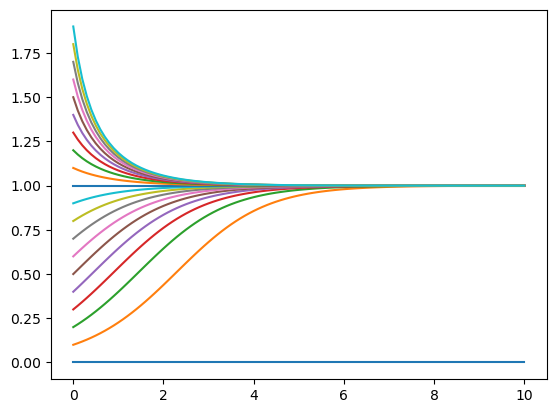

In [48]:
x0s = np.arange(0, 2+0.1, 0.1)
for i in range(x0s.shape[0]-1):
    for j in range(t.shape[0]-1):
        x[0] = x0s[i]
        x[j+1] = x[j] + dt * dxdt(x[j])
        
    plt.plot(t, x)

In [49]:
x[0] = x0

Plotting our solution

Take a single initial condition and simulate the ODE with different values for $\Delta t$. Plot the estimated solutions on the same graph. Describe what you observe.

## 4th order Runge-Kutta method 
$$x_{n+1} = x_n + \frac{1}{6}\left(k_1+2k_2+2k_3+k_4\right)$$
where
\begin{align}k_1&=\Delta t f(x_n) \\
k_2&=\Delta t f(x_n+\tfrac{1}{2}k_1) \\
k_3&=\Delta t f(x_n+\tfrac{1}{2}k_2) \\
k_4&=\Delta t f(x_n+k_3) \end{align}

In [42]:
xRK = np.zeros(t.shape)
xRK[0] = x0

In [43]:
for j in range(t.shape[0]-1):
    k1 = dt * dxdt(xRK[j])
    k2 = dt * dxdt(xRK[j] + 1/2 * k1)
    k3 = dt * dxdt(xRK[j] + 1/2 * k2)
    k4 = dt * dxdt(xRK[j] + k3)

    xRK[j+1] = xRK[j] + 1/6*(k1 + 2 * k2 + 2 * k3  + k4)

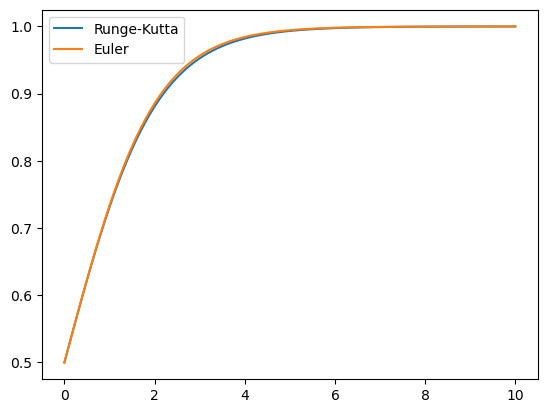

In [45]:
plt.plot(t, xRK, label = "Runge-Kutta")
plt.plot(t, x, label = "Euler")
plt.legend()


## Streamplots

A useful tool for studying how a system behaves is a streamplot/slope field. It shows the rate direction our solution ($x$) moves in at every point in time and space. The below code create a streamplot for the ODE $\dot{x}=x(1-x)$

In [57]:
# meshgrid returns an array of 2 matrices, the first gives all xticks and the second gives all yticks
# code can then use all ii entries of the 2 matrices as the 2 initial coords 
t = np.arange(t_start, t_final + dt, dt)
x_range = np.linspace(0, 2, 100)
tm, xm = np.meshgrid(t, x_range)
dxdt_m = dxdt(xm) # Flow in x direcction    # Recall x_dot = f(x, t).
dt_m = np.ones(tm.shape)                    # and t_dot = 1 since time increases linearly with time.


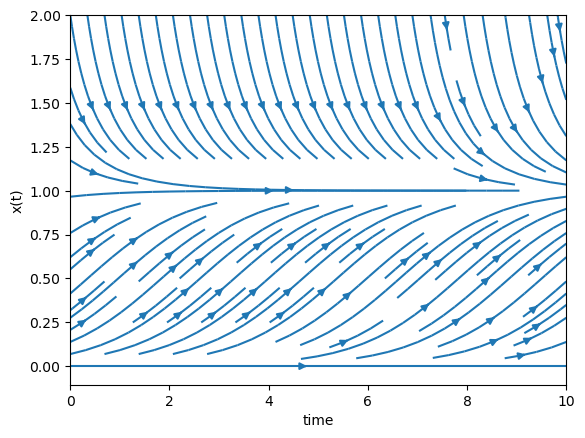

In [60]:
plt.streamplot(t, x_range, dt_m, dxdt_m)
plt.xlabel("time")
plt.ylabel("x(t)");